In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap
from tensorflow.keras.models import load_model
import torch
import torch.nn as nn
import joblib
import json
from pathlib import Path
from datetime import datetime

import sys
sys.path.append("../../tools")
import architec as acht
import evaluation as eva
import prepare as prep
import functions as func


In [2]:
import importlib
#importlib.reload(acht)
#importlib.reload(prep)
#importlib.reload(func)


In [3]:
def richness_to_tag(richness_list):
    return "_".join(map(str, richness_list))

def get_model_dir(richness_list, rep):
    tag = richness_to_tag(richness_list)
    return Path(f"../../saved_models/sta_entropy/sp{tag}_MD_transpt_r{rep}")


In [6]:
train_richness_sets = [[10], [7, 8, 9], [8, 9]]
#train_richness_sets = [[10], [11,12,13], [11,12]]
#train_richness_sets = [[10], [8,9,11,12], [9,11]]

all_metrics = []

for train_richness in train_richness_sets:
    for rep in range(3):
        # Model loading
        load_dir = get_model_dir(train_richness, rep + 1)
        # scaler
        scaler_g = joblib.load(load_dir / "scaler_g.pkl")
        scaler_d = joblib.load(load_dir / "scaler_d.pkl")

        # config
        with open(load_dir / "config.json") as f:
            config = json.load(f)

        NumSpecies = config["NumSpecies"]
        featgam = config["featgam"]
        task_num = config["task_num"]
        # n_class = config["n_class"]
        embed_dim = config["embed_dim"]
        num_heads = config["num_heads"]
        ff_dim = config["ff_dim"]

        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        model = acht.MDTrans2(NumSpecies).to(device)

        model.load_state_dict(torch.load(load_dir / "model.pt", map_location=device))

        split_df = pd.read_csv(f"../Fig2/split_MD_{rep+1}.csv")
        folder_path = "../../Databases/Ver1.9/ver1.9.6_upto20"

        #-----different richness testset--------
        for rich in range(3, 21):
            narray_te = prep.load_split_dataset(
                split_df,
                folder_path,
                richness_list=[rich],
                #richness_list=list(range(3,21)),
                subset="te"
            )

            Xg_te, XA_te, Xd_te, y_te, idx_te = prep.prepare_test(
                narray_te,
                NumSpecies,
                featgam,
                scaler_g,
                scaler_d,
                task_num,
                sample_size=17000,                
                random_state=42
            )

            Xg_te = torch.as_tensor(Xg_te, dtype=torch.float32, device=device)
            XA_te = torch.as_tensor(XA_te, dtype=torch.float32, device=device)
            Xd_te = torch.as_tensor(Xd_te, dtype=torch.float32, device=device)

            model.eval()
            with torch.no_grad():
                pred = model(Xg_te, XA_te, Xd_te)
                y_pred = pred.cpu().numpy().ravel()

            metrics = eva.eval_regression(y_te, y_pred)
            metrics["rep"] = rep + 1
            metrics["test_richness"] = rich
            metrics["train_richness"] = (train_richness)
            metrics["train_richness_tag"] = "_".join(map(str, train_richness))     
            all_metrics.append(metrics)

df_metrics = pd.DataFrame(all_metrics)
#df_metrics.to_pickle("Experience_transfer.pkl")
# df_metrics.to_pickle("Exploratory_foresight.pkl")
df_metrics.to_pickle("Interpolation.pkl")


te shape = (19003, 465)
te shape = (20106, 465)


KeyboardInterrupt: 

In [9]:
predict_types = ["upward", "downward", "interpolation"]
predict_type = predict_types[1]

df_metrics = pd.read_pickle(f"{predict_type}.pkl")

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis label (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick label (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

colors = ["#40a6bd", "#cf8c51", "#F8CE45", '#626c83']
highlight_markers = ['*', '^', 'D']  # star, triangle, diamond
plot_sizes = [85, 45, 30]

plot_df = (df_metrics.groupby(["train_richness_tag", "test_richness"])["R2"]
               .agg(mean="mean", min="min", max="max").reset_index())


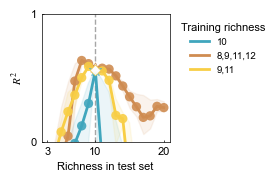

In [ ]:
plt.figure(figsize=(1.6, 1.6), dpi=100)

for i, (train_tag, grp) in enumerate(
        plot_df.groupby("train_richness_tag")):

    grp = grp.sort_values("test_richness")
    color = colors[i % len(colors)]

    # Draw lines, no points
    plt.plot(
        grp["test_richness"], grp["mean"],
        color=color, linewidth=2, alpha=1,
        label=train_tag.replace("_", ",")
    )

    # Normal points: circles, excluding richness = 10
    grp_other = grp[grp["test_richness"] != 10]
    plt.scatter(
        grp_other["test_richness"], grp_other["mean"],
        s=45, marker='o', color=color,
        edgecolors='none', alpha=0.9, zorder=4, rasterized=True
    )

    # Highlighted points
    grp10 = grp[grp["test_richness"] == 10]
    plt.scatter(
        grp10["test_richness"], grp10["mean"],
        s=plot_sizes[i], marker=highlight_markers[i],
        color='white', edgecolors=color,
        linewidths=0.5, alpha=0.9, zorder=5, rasterized=True
    )

    poly = plt.fill_between(
        grp["test_richness"], grp["min"], grp["max"],
        color=color, alpha=0.1
    )
    poly.set_rasterized(True)

# Mark the vertical dashed line at richness = 10
plt.axvline(x=10, color='grey', linestyle='--', linewidth=1, alpha=0.7, zorder=0)

plt.xlabel("Richness in test set")
plt.ylabel(r"$R^2$")
plt.xticks([3,10,20])
plt.ylim(0,1)
plt.yticks([0,1])
plt.tick_params(direction='in')
plt.grid(False)
plt.legend(
    title="Training richness",
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)
plt.subplots_adjust(left=0.18, right=0.98, bottom=0.18, top=0.98)

# plt.savefig(
#     f"{predict_type}_R2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
#     dpi=1000,
#     bbox_inches='tight', # auto-crop extra blank areas around the figure
#     transparent=True
# )

plt.show()
